<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

In [4]:
pip install pandas matplotlib

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 3.4 MB/s eta 0:00:04
   ----- ---------------------------------- 1.6/11.3 MB 4.2 MB/s eta 0:00:03
   ---------- ----------------------------- 2.9/11.3 MB 4.7 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.3 MB 4.9 MB/s eta 0:00:02
   ------------------ --------------------- 5.2/11.3 MB 5.1 MB/s eta 0:00:02
   ----------------------- ---------------- 6.6/11.3 MB 5.4 MB/s eta 0:00:01
   --------------------------- ------------ 7.9/11.3 MB 5.5 MB/s eta 0:00:01
   ------------------------------- -------- 8.9/11.3 MB 5.4 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.3 MB 5.3 MB/s eta 0:00:01
   ------------------------------------- -- 10.7/11.3 MB 5.2 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 5.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 4.9 MB/s  0:00:02
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


,orderid,customerid,employeeid,orderdate,shipperid
0,10248,90,5,1996-07-04,3
1,10249,81,6,1996-07-05,1
2,10250,34,4,1996-07-08,2
3,10251,84,3,1996-07-08,1
4,10252,76,4,1996-07-09,2


Prvá objednávka: 1996-07-04 00:00:00
Posledná objednávka: 1997-02-12 00:00:00
Počet objednávok: 196

Počet objednávok podľa roku:
orderdate
1996    152
1997     44
Name: count, dtype: int64

Počet objednávok podľa mesiaca:
orderdate
1996-07    22
1996-08    25
1996-09    23
1996-10    26
1996-11    25
1996-12    31
1997-01    33
1997-02    11
Freq: M, Name: count, dtype: int64


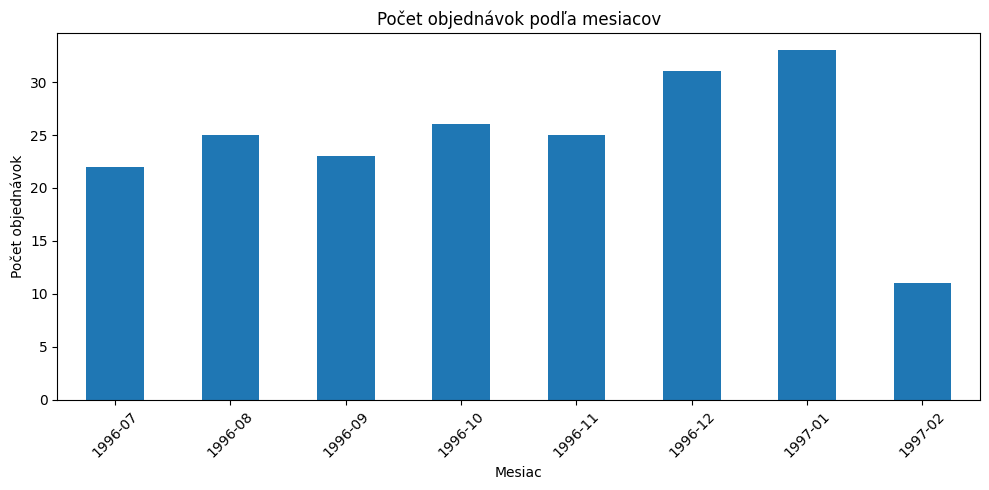

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Načítanie súboru
df = pd.read_csv("orders(1).csv", parse_dates=["orderdate"])

# Zobrazenie prvých riadkov
display(df.head())

# Časový rozsah objednávok
print("Prvá objednávka:", df["orderdate"].min())
print("Posledná objednávka:", df["orderdate"].max())

# Celkový počet objednávok
print("Počet objednávok:", len(df))

# Počet objednávok podľa roku
print("\nPočet objednávok podľa roku:")
print(df["orderdate"].dt.year.value_counts().sort_index())

# Počet objednávok podľa mesiaca
mesiace = df["orderdate"].dt.to_period("M").value_counts().sort_index()

print("\nPočet objednávok podľa mesiaca:")
print(mesiace)

# Graf počtu objednávok podľa mesiacov
mesiace.plot(kind="bar", figsize=(10, 5))

plt.title("Počet objednávok podľa mesiacov")
plt.xlabel("Mesiac")
plt.ylabel("Počet objednávok")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [9]:
hranica = pd.Timestamp("1997-01-01")

historical_orders = df[df["orderdate"] < hranica].copy()

new_orders = df[df["orderdate"] >= hranica].copy()

print("Historické objednávky:", len(historical_orders))
print("Novšie objednávky:", len(new_orders))

print("Všetky objednávky:", len(df))
print("Súčet oboch skupín:", len(historical_orders) + len(new_orders))

print("Kontrola:", len(historical_orders) + len(new_orders) == len(df))

Historické objednávky: 152
Novšie objednávky: 44
Všetky objednávky: 196
Súčet oboch skupín: 196
Kontrola: True


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [11]:
pip install psycopg2-binary sqlalchemy

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ------- -------------------------------- 0.5/2.8 MB 4.2 MB/s eta 0:00:01
   ------------------------------ --------- 2.1/2.8 MB 6.2 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 5.9 MB/s  0:00:00
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ------------------------ --------------- 1.3/2.2 MB 6.1 MB/s eta 0:00:01
   -------------------------------------- - 2.1/2.2 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 4.0 MB/s  0:00:00

   ------------- -------------------------- 1/3 [greenlet]
   ------------- -------------------------- 1/3 [greenlet]
   -------------------------- ------------- 2/3 [sqlalchemy]
   -------------------------- ------------- 2/3 [sqlalchemy]
   -------------------------- ------------- 2/3 [sqlalchemy]
   -------------------------- ------------- 2/3 [sqlalchemy]
   -------------------------- ------------- 2/3 [

In [12]:
import pandas as pd
import psycopg2
from psycopg2 import sql
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# 1. Vytvorenie databázy
conn = psycopg2.connect(
    host="localhost",
    database="postgres",
    user="postgres",
    password="TVOJE_HESLO"
)

conn.autocommit = True
cur = conn.cursor()

try:
    cur.execute(
        sql.SQL("CREATE DATABASE {}").format(
            sql.Identifier("orders_practice")
        )
    )
    print("Databáza bola vytvorená.")
except psycopg2.errors.DuplicateDatabase:
    print("Databáza už existuje.")

cur.close()
conn.close()

# 2. Pripojenie k databáze
url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password="TVOJE_HESLO",
    host="localhost",
    port=5432,
    database="orders_practice"
)

engine = create_engine(url)

# 3. Vymazanie starej tabuľky
with engine.begin() as conn:
    conn.exec_driver_sql("DROP TABLE IF EXISTS orders")

# 4. Nahratie objednávok z CSV do PostgreSQL
df.to_sql(
    "orders",
    engine,
    if_exists="append",
    index=False
)

# 5. Nastavenie primárneho kľúča
with engine.begin() as conn:
    conn.exec_driver_sql(
        "ALTER TABLE orders ADD PRIMARY KEY (orderid)"
    )

# 6. Kontrola počtu záznamov
with engine.connect() as conn:
    pocet = conn.exec_driver_sql(
        "SELECT COUNT(*) FROM orders"
    ).scalar()

print("Počet objednávok v databáze:", pocet)
print("Počet objednávok v DataFrame:", len(df))


OperationalError: connection to server at "localhost" (::1), port 5432 failed: Connection refused (0x0000274D/10061)
	Is the server running on that host and accepting TCP/IP connections?
connection to server at "localhost" (127.0.0.1), port 5432 failed: Connection refused (0x0000274D/10061)
	Is the server running on that host and accepting TCP/IP connections?


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [13]:
pocet_objednavok = len(historical_orders)

pocet_zakaznikov = historical_orders["customerid"].nunique()

pocet_dopravca_3 = (historical_orders["shipperid"] == 3).sum()

percento = (pocet_dopravca_3 / pocet_objednavok) * 100

print("Počet objednávok:", pocet_objednavok)
print("Počet zákazníkov:", pocet_zakaznikov)
print("Počet objednávok s shipperid = 3:", pocet_dopravca_3)
print("Percento objednávok s shipperid = 3:", round(percento, 2), "%")

Počet objednávok: 152
Počet zákazníkov: 66
Počet objednávok s shipperid = 3: 58
Percento objednávok s shipperid = 3: 38.16 %


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [15]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password="TVOJE_HESLO",
    host="localhost",
    port=5432,
    database="orders_practice"
)

engine = create_engine(url)

In [16]:
from sqlalchemy import text
import pandas as pd

SAMPLE_SIZE = 44

cutoff = "1997-01-01"

with engine.connect() as conn:
    new_orders_sample = pd.read_sql(
        text("""
            SELECT *
            FROM orders
            WHERE orderdate >= :cutoff
            ORDER BY orderdate, orderid
            LIMIT :limit
        """),
        conn,
        params={
            "cutoff": cutoff,
            "limit": SAMPLE_SIZE
        }
    )

print("Počet vybraných objednávok:", len(new_orders_sample))
display(new_orders_sample.head())


OperationalError: (psycopg2.OperationalError) connection to server at "localhost" (::1), port 5432 failed: Connection refused (0x0000274D/10061)
	Is the server running on that host and accepting TCP/IP connections?
connection to server at "localhost" (127.0.0.1), port 5432 failed: Connection refused (0x0000274D/10061)
	Is the server running on that host and accepting TCP/IP connections?

(Background on this error at: https://sqlalche.me/e/20/e3q8)

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [17]:
import time

EVENT_DELAY_SEC = 0.04
MICRO_WINDOW_SEC = 0.30

streaming_count = 0
streaming_shipper3 = 0

streaming_results = []

micro_batch = []
micro_results = []
micro_start = time.time()

batch_count = 0
batch_shipper3 = 0
batch_percent = 0


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [19]:
for _, order in new_orders.sort_values(
    ["orderdate", "orderid"]
).iterrows():

    streaming_count += 1

    if order["shipperid"] == 3:
        streaming_shipper3 += 1

    percento = (streaming_shipper3 / streaming_count) * 100

    streaming_results.append({
        "čas": time.time(),
        "počet": streaming_count,
        "percento": percento
    })

    micro_batch.append(order)

    time.sleep(EVENT_DELAY_SEC)

    if time.time() - micro_start >= MICRO_WINDOW_SEC:

        pocet = len(micro_batch)
        dopravca3 = sum(
            1 for o in micro_batch if o["shipperid"] == 3
        )

        micro_results.append({
            "čas": time.time(),
            "počet": pocet,
            "percento": (dopravca3 / pocet) * 100
        })

        micro_batch = []
        micro_start = time.time()

if micro_batch:
    pocet = len(micro_batch)
    dopravca3 = sum(
        1 for o in micro_batch if o["shipperid"] == 3
    )

    micro_results.append({
        "čas": time.time(),
        "počet": pocet,
        "percento": (dopravca3 / pocet) * 100
    })

    micro_batch = []

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [20]:
if micro_batch:
    pocet = len(micro_batch)

    dopravca3 = sum(
        1 for o in micro_batch if o["shipperid"] == 3
    )

    micro_results.append({
        "čas": time.time(),
        "počet": pocet,
        "percento": (dopravca3 / pocet) * 100
    })

    micro_batch = []

batch_count = len(new_orders)

batch_shipper3 = (new_orders["shipperid"] == 3).sum()

batch_percent = (batch_shipper3 / batch_count) * 100

print("BATCH")
print("Počet objednávok:", batch_count)
print("Objednávky s shipperid = 3:", batch_shipper3)
print("Percento:", round(batch_percent, 2), "%")

streaming_percent = (
    streaming_shipper3 / streaming_count
) * 100

print("\nSTREAMING:", round(streaming_percent, 2), "%")
print("BATCH:", round(batch_percent, 2), "%")

print(
    "Výsledky sú rovnaké:",
    round(streaming_percent, 2) == round(batch_percent, 2)
)

BATCH
Počet objednávok: 44
Objednávky s shipperid = 3: 10
Percento: 22.73 %

STREAMING: 22.73 %
BATCH: 22.73 %
Výsledky sú rovnaké: True


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

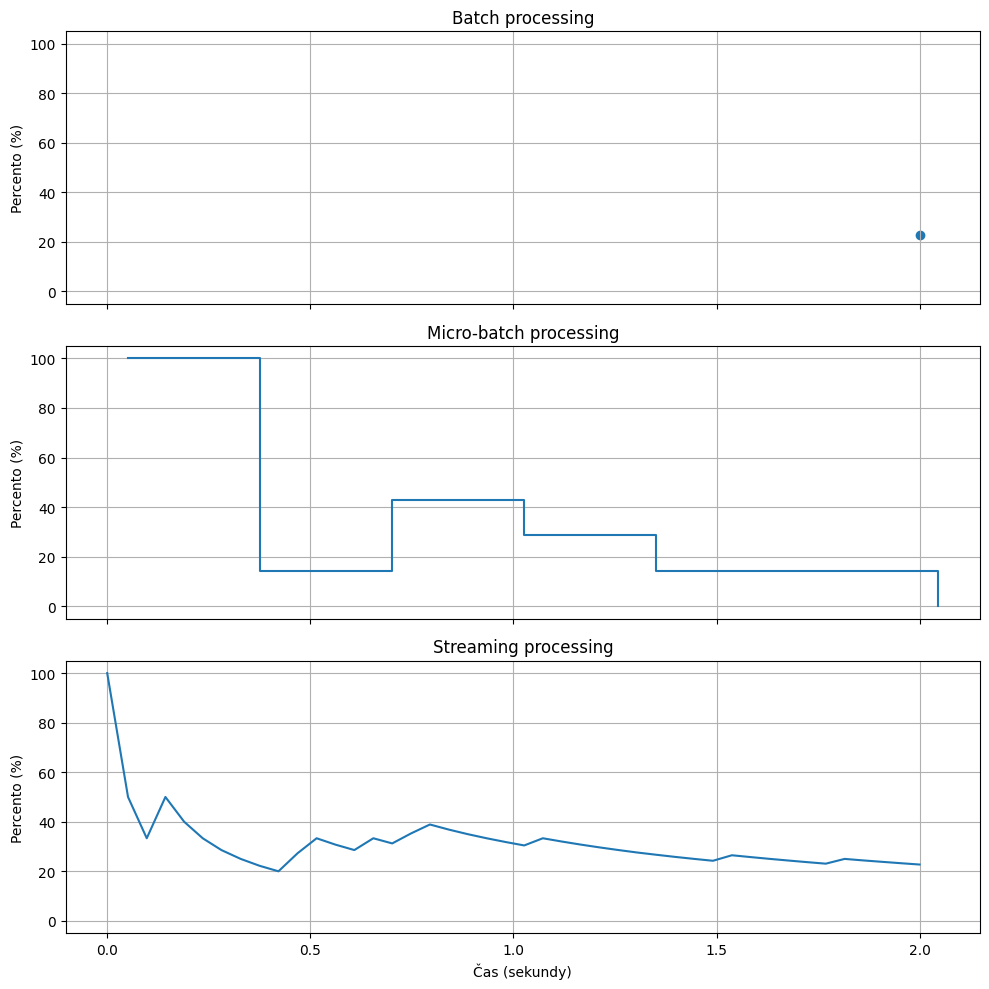

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

micro_df = pd.DataFrame(micro_results)
streaming_df = pd.DataFrame(streaming_results)

if len(streaming_df) > 0:
    zaciatok = streaming_df["čas"].iloc[0]

    streaming_df["čas"] = streaming_df["čas"] - zaciatok

if len(micro_df) > 0:
    micro_df["čas"] = micro_df["čas"] - zaciatok

fig, axes = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(10, 10))

axes[0].scatter(
    [streaming_df["čas"].iloc[-1]],
    [batch_percent]
)
axes[0].set_title("Batch processing")
axes[0].set_ylabel("Percento (%)")
axes[0].grid(True)

axes[1].step(
    micro_df["čas"],
    micro_df["percento"],
    where="post"
)
axes[1].set_title("Micro-batch processing")
axes[1].set_ylabel("Percento (%)")
axes[1].grid(True)

axes[2].plot(
    streaming_df["čas"],
    streaming_df["percento"]
)
axes[2].set_title("Streaming processing")
axes[2].set_xlabel("Čas (sekundy)")
axes[2].set_ylabel("Percento (%)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

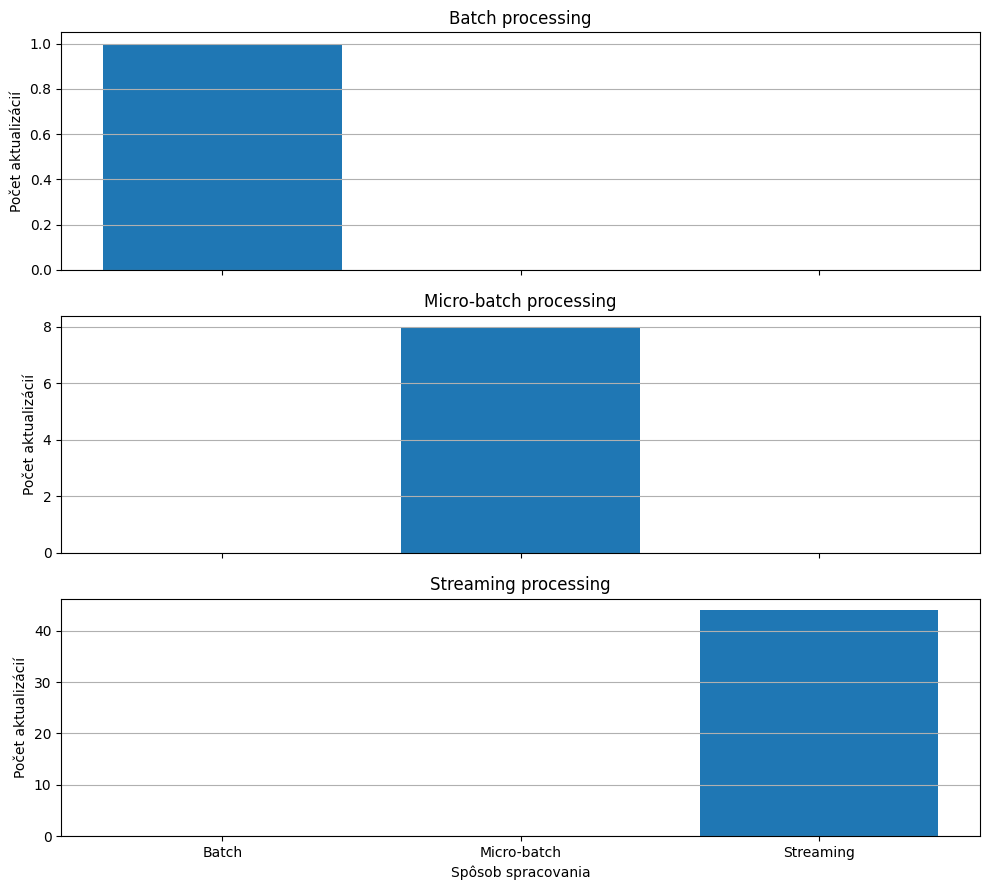

Batch: 1
Micro-batch: 8
Streaming: 44


In [24]:
import matplotlib.pyplot as plt

batch_updates = 1
micro_updates = len(micro_results)
streaming_updates = len(streaming_results)

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 9))

axes[0].bar(["Batch"], [batch_updates])
axes[0].set_title("Batch processing")
axes[0].set_ylabel("Počet aktualizácií")
axes[0].grid(axis="y")

axes[1].bar(["Micro-batch"], [micro_updates])
axes[1].set_title("Micro-batch processing")
axes[1].set_ylabel("Počet aktualizácií")
axes[1].grid(axis="y")

axes[2].bar(["Streaming"], [streaming_updates])
axes[2].set_title("Streaming processing")
axes[2].set_ylabel("Počet aktualizácií")
axes[2].set_xlabel("Spôsob spracovania")
axes[2].grid(axis="y")

plt.tight_layout()
plt.show()

print("Batch:", batch_updates)
print("Micro-batch:", micro_updates)
print("Streaming:", streaming_updates)

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>